# SMBHB WDM Pixel Clustering Workflow

This notebook explains and runs the clustering pipeline implemented in `cluster/`.

The goal is to learn a compact representation of LISA A/E-channel WDM time-frequency patches for simulated SMBHB signals, then cluster those learned representations with HDBSCAN. The clustering itself is unsupervised, but we keep the SMBHB physical parameters as metadata so clusters can be interpreted afterward.

## Pipeline Summary

The workflow has eight stages:

1. Sample SMBHB parameters over the requested physical range.
2. Generate SMBHB waveforms with `phenomxpy`.
3. Run the existing LISA link/TDI simulation pipeline.
4. Estimate an off-source A/E noise PSD from one reference simulation.
5. Whiten A/E time series using that PSD.
6. Convert whitened A/E time series into fixed-size WDM patches.
7. Train a CNN autoencoder and extract latent vectors.
8. Cluster latent vectors with HDBSCAN and evaluate clusters against metadata.

The important design choice is that HDBSCAN does not cluster raw pixels. It clusters the autoencoder latent vectors, which should represent signal morphology more compactly than the full WDM image.

## Environment

Use the updated `lisa-tf` environment:

```bash
conda activate lisa-tf
```

The ML dependencies required by this notebook are `torch`, `scikit-learn`, and `hdbscan`.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "cluster":
    PROJECT_ROOT = PROJECT_ROOT.parent

RUNS_DIR = PROJECT_ROOT / "cluster" / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print(PROJECT_ROOT)
print(RUNS_DIR)

/Users/shubhanshutiwari/IdeaProjects/LISA-TF
/Users/shubhanshutiwari/IdeaProjects/LISA-TF/cluster/runs


In [2]:
import torch
import sklearn
import hdbscan

print("torch", torch.__version__)
print("sklearn", sklearn.__version__)
print("hdbscan imported")

torch 2.10.0
sklearn 1.8.0
hdbscan imported


## 1. Sample SMBHB Parameters

The default sampler uses:

- total mass `M_total` sampled log-uniformly from `1e4` to `1e8` solar masses,
- symmetric mass ratio `eta` sampled uniformly from `0.15` to `0.25`,
- luminosity distance sampled log-uniformly,
- sky location, inclination, phase, and aligned spins sampled from broad ranges.

`eta=0.25` corresponds to equal masses. The repo's older folder labels such as `eta-1_5` mean `eta=0.15`, not a physical value of `1.5`.

In [3]:
from cluster.config import PipelineConfig
from cluster.parameters import sample_smbhb_catalog, write_catalog

config = PipelineConfig()

# Start small. Full LISA simulations are expensive.
catalog = sample_smbhb_catalog(20, config.parameters, seed=12345)
catalog_path = write_catalog(catalog, RUNS_DIR / "notebook_catalog.csv")

catalog.head()

,source_id,total_mass,m1,m2,q,eta,distance_mpc,s1,s2,f_min_hz,iota,phi_ref,ra,dec
0,smbhb_00000,8.116038e+04,6.517601e+04,1.598437e+04,0.245249,0.158159,3870.594274,-0.244768,-0.202435,0.0001,0.876715,1.637267,3.033281,-0.904845
1,smbhb_00001,1.849411e+05,1.460749e+05,3.886619e+04,0.266070,0.165990,7332.221694,-0.004369,-0.253739,0.0001,2.634171,1.131794,5.417088,-1.010652
2,smbhb_00002,1.546899e+07,1.170825e+07,3.760740e+06,0.321204,0.184010,2694.629288,0.250531,0.111120,0.0001,0.657080,4.774419,1.566150,-1.301965
3,smbhb_00003,5.070125e+06,3.707574e+06,1.362551e+06,0.367505,0.196519,14976.859739,0.118057,0.036968,0.0001,1.993424,1.095625,1.559263,0.580639
4,smbhb_00004,3.668075e+05,2.827523e+05,8.405517e+04,0.297275,0.176642,2160.037113,-0.419128,0.375074,0.0001,1.346783,3.885485,1.967300,-1.008568


In [ ]:
catalog[["source_id", "total_mass", "eta", "q", "distance_mpc", "ra", "dec"]].describe()

## 2. Generate Waveforms And Run LISA Simulations

For each sampled source, the pipeline generates `hplus` and `hcross` waveforms and feeds them to the existing repository pipeline:

- waveform preparation,
- LISA orbit setup,
- six-link response,
- noisy instrument simulation,
- A/E/T TDI products.

This is the slowest stage. Keep `limit` small until the full path is validated. The default output directory is `cluster/runs/simulations/<source_id>/`.

In [4]:
from cluster.simulation import run_catalog_simulations

# This cell runs real LISA simulations and can take time.
# Increase limit only after the first few sources complete cleanly.
RUN_REAL_SIMULATIONS = False

if RUN_REAL_SIMULATIONS:
    work_dirs = run_catalog_simulations(
        catalog,
        runs_root=RUNS_DIR / "simulations",
        waveform_config=config.waveform,
        simulation_config=config.simulation,
        limit=2,
        make_plots=False,
    )
    work_dirs
else:
    print("Set RUN_REAL_SIMULATIONS = True to generate new simulations.")

Set RUN_REAL_SIMULATIONS = True to generate new simulations.


## 3. Estimate Off-Source A/E Noise PSD

The autoencoder should see noise-whitened maps, otherwise clustering can be dominated by the detector noise shape instead of signal morphology.

The PSD estimator reads one noisy TDI simulation, finds the GW signal window, removes a guard region around the signal, and computes Welch PSDs from off-source A and E samples.

The same PSD is then used to whiten A/E for every source in the dataset.

In [5]:
from cluster.psd import estimate_noise_psd_from_work_dir, load_noise_psd

psd_path = RUNS_DIR / "notebook_noise_psd.csv"

# Existing reference simulation in this repo.
reference_work_dir = PROJECT_ROOT / "lisa_link_sim" / "eta-1_5"

psd = estimate_noise_psd_from_work_dir(
    reference_work_dir,
    config=config.psd,
    tdi_generation=config.simulation.tdi_generation,
    output_csv=psd_path,
)

psd.head()

,frequency_hz,S_A,S_E
0,0.000000,3.555786e-12,6.803681e-12
1,0.000610,3.300231e-12,5.690584e-12
2,0.001221,4.754295e-12,8.127499e-12
3,0.001831,1.250996e-11,2.282391e-11
4,0.002441,2.712700e-11,5.659143e-11


<Axes: title={'center': 'Off-source A/E PSD'}, xlabel='frequency_hz'>

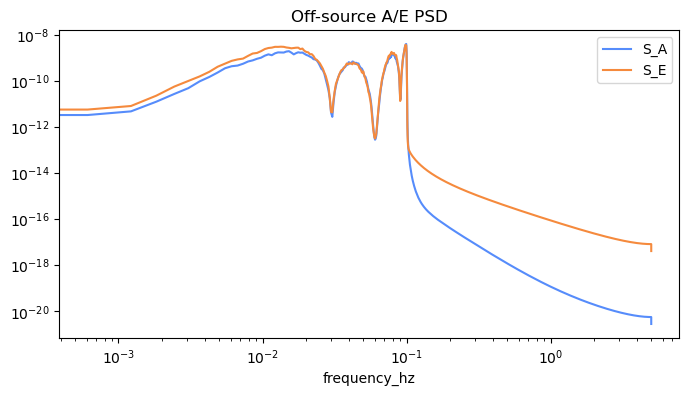

In [6]:
psd.plot(x="frequency_hz", y=["S_A", "S_E"], logx=True, logy=True, figsize=(8, 4), title="Off-source A/E PSD")

## 4. Build Fixed-Size A/E WDM Patches

Each source becomes one tensor with shape:

```text
[channels, frequency_bins, time_bins] = [2, 128, 128]
```

The two channels are A and E. The patch extraction steps are:

1. read noisy A/E TDI time series,
2. whiten each channel using the off-source PSD,
3. downsample to the configured WDM input cadence,
4. compute WDM power maps,
5. crop around the signal peak,
6. resize to a fixed grid,
7. apply `log1p` and robust per-patch normalization.

For this demonstration, we can build patches from two existing simulations already present in the repo.

In [7]:
from cluster.wdm_pixels import build_dataset, load_dataset

existing_work_dirs = [
    PROJECT_ROOT / "lisa_link_sim" / "eta-1_5",
    PROJECT_ROOT / "lisa_link_sim" / "z2_eta-2_5",
]

dataset_path = RUNS_DIR / "notebook_existing_patches.npz"
metadata_path = RUNS_DIR / "notebook_existing_patches_metadata.csv"

build_dataset(
    existing_work_dirs,
    psd=psd,
    wdm_config=config.wdm,
    psd_config=config.psd,
    output_npz=dataset_path,
    metadata_csv=metadata_path,
    catalog=None,
    tdi_generation=config.simulation.tdi_generation,
)

x, source_ids = load_dataset(dataset_path)
x.shape, source_ids

((2, 2, 128, 128), array(['eta-1_5', 'z2_eta-2_5'], dtype='<U10'))

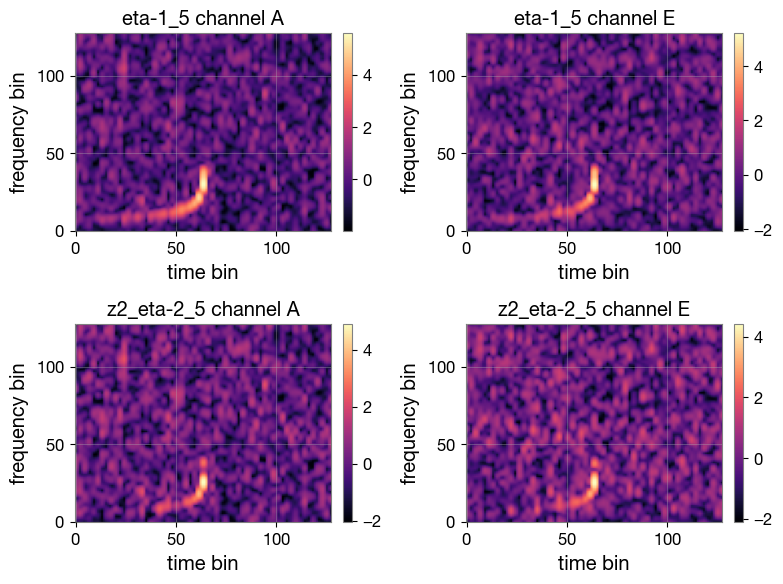

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(x), 2, figsize=(8, 3 * len(x)), squeeze=False)
for row, source_id in enumerate(source_ids.astype(str)):
    for col, channel in enumerate(["A", "E"]):
        im = axes[row, col].imshow(x[row, col], origin="lower", aspect="auto", cmap="magma")
        axes[row, col].set_title(f"{source_id} channel {channel}")
        axes[row, col].set_xlabel("time bin")
        axes[row, col].set_ylabel("frequency bin")
        fig.colorbar(im, ax=axes[row, col], fraction=0.046, pad=0.04)
plt.tight_layout()

## 5. Train The CNN Autoencoder

The autoencoder is trained to reconstruct each A/E WDM patch:

```text
WDM patch -> CNN encoder -> latent vector -> CNN decoder -> reconstructed patch
```

The latent vector is the feature representation used for clustering. This is useful because clustering raw WDM pixels is high-dimensional and sensitive to small shifts, while the latent vector should capture broader morphology.

A real training set should contain many more than two samples. The two existing patches are useful only for checking the mechanics.

In [9]:
from cluster.autoencoder import train_autoencoder

TRAIN_AUTOENCODER = False

if TRAIN_AUTOENCODER:
    model_path, embeddings_path, history_path = train_autoencoder(
        dataset_path,
        latent_dim=16,
        epochs=5,
        batch_size=2,
        learning_rate=config.autoencoder.learning_rate,
        weight_decay=config.autoencoder.weight_decay,
        validation_fraction=0.0,
        seed=config.autoencoder.seed,
        model_path=RUNS_DIR / "notebook_autoencoder.pt",
        embeddings_npz=RUNS_DIR / "notebook_embeddings.npz",
        history_csv=RUNS_DIR / "notebook_training_history.csv",
    )
    print(model_path)
    print(embeddings_path)
    print(history_path)
else:
    print("Set TRAIN_AUTOENCODER = True after building a larger dataset.")

Set TRAIN_AUTOENCODER = True after building a larger dataset.


## 6. Cluster With HDBSCAN

HDBSCAN clusters the latent vectors, not the WDM images directly.

Why HDBSCAN is a good first choice:

- it does not require choosing the number of clusters in advance,
- it can mark ambiguous points as noise with label `-1`,
- it handles clusters with different densities better than simple k-means.

For a small proof-of-concept dataset, use a small `min_cluster_size`. For scientific runs, increase it so clusters are supported by multiple independent simulations.

In [10]:
from cluster.clustering import run_hdbscan

RUN_HDBSCAN = False

if RUN_HDBSCAN:
    labels_path = run_hdbscan(
        RUNS_DIR / "notebook_embeddings.npz",
        min_cluster_size=5,
        min_samples=None,
        metric="euclidean",
        labels_csv=RUNS_DIR / "notebook_hdbscan_labels.csv",
    )
    labels = pd.read_csv(labels_path)
    labels.head()
else:
    print("Set RUN_HDBSCAN = True after training the autoencoder on a larger dataset.")

Set RUN_HDBSCAN = True after training the autoencoder on a larger dataset.


## 7. Evaluate And Interpret Clusters

The clustering objective is unsupervised, but the sampled SMBHB parameters are retained for interpretation. After clustering, inspect whether clusters correlate with meaningful physical or observational quantities:

- total mass,
- symmetric mass ratio `eta`,
- mass ratio `q`,
- distance or SNR proxy,
- track duration,
- merger visibility inside the patch.

A useful clustering should not merely separate sources by amplitude or padding artifacts. If clusters correlate only with distance or normalization choices, revisit whitening and patch normalization.

In [11]:
from cluster.evaluation import evaluate_clusters

RUN_EVALUATION = False

if RUN_EVALUATION:
    metrics_path, summary_path = evaluate_clusters(
        embeddings_npz=RUNS_DIR / "notebook_embeddings.npz",
        labels_csv=RUNS_DIR / "notebook_hdbscan_labels.csv",
        metadata_csv=metadata_path,
        metrics_json=RUNS_DIR / "notebook_cluster_metrics.json",
        summary_csv=RUNS_DIR / "notebook_cluster_summary.csv",
    )
    print(json.loads(metrics_path.read_text()))
    pd.read_csv(summary_path)
else:
    print("Set RUN_EVALUATION = True after clustering.")

Set RUN_EVALUATION = True after clustering.


## Recommended First Scientific Run

Use this sequence once the notebook demonstration works:

```bash
conda run -n lisa-tf python -m cluster.cli sample --n-sources 100
conda run -n lisa-tf python -m cluster.cli simulate --limit 10
conda run -n lisa-tf python -m cluster.cli estimate-psd
conda run -n lisa-tf python -m cluster.cli build-dataset
conda run -n lisa-tf python -m cluster.cli train-autoencoder
conda run -n lisa-tf python -m cluster.cli cluster
conda run -n lisa-tf python -m cluster.cli evaluate
```

Then scale from `10` to `100+` simulations. For reliable unsupervised structure, the dataset should eventually be much larger than the latent dimension and the requested HDBSCAN `min_cluster_size`.

## Failure Modes To Watch

- Clusters separate by SNR or distance instead of morphology.
- Clusters separate by coalescence-time placement or patch padding.
- Low-mass and high-mass systems need different WDM resolutions.
- The autoencoder reconstructs background noise better than signal tracks.
- HDBSCAN returns mostly `-1`, meaning the latent space does not have stable density structure at the chosen settings.

The immediate diagnostic is to plot embeddings colored by `total_mass`, `eta`, `distance_mpc`, reconstruction loss, and cluster label.